Pierre Cordier, DVM, PhD, Dipl.ECVP
23/11/2026

In [5]:
# Import general packages
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path
import cv2

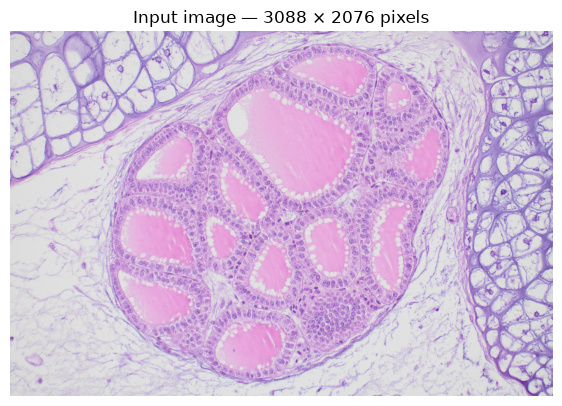

In [6]:
# Load and inspect the image
IMAGE_PATH = Path("C:/Users/pcordier/Documents/Computational-pathology/14923C-N1-Thyroid.tif")
image_pil = Image.open(IMAGE_PATH).convert("RGB")

rgb = np.asarray(image_pil)
height, width = rgb.shape[:2]

plt.figure(figsize=(7, 5))
plt.imshow(rgb)
plt.title(f"Input image — {width} × {height} pixels")
plt.axis("off")
plt.show()

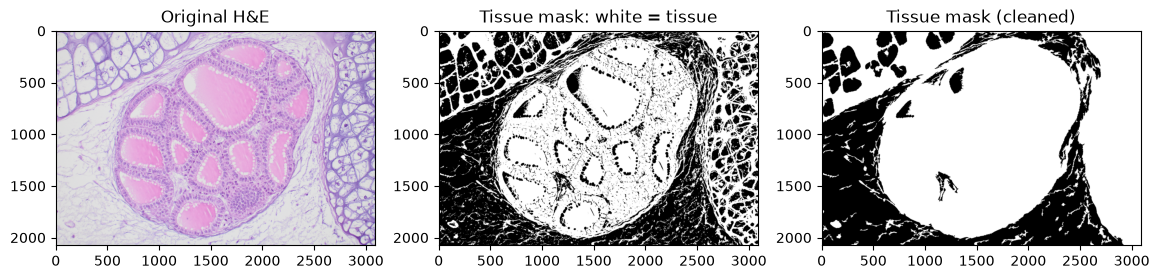

In [8]:
# Basic tissue mask
from skimage.morphology import remove_small_objects, remove_small_holes

# Mask based on Green channel
gray = rgb[:, :, 1]
tissue_mask = gray < 200

# Optional cleanup
mask_clean = remove_small_objects(tissue_mask, max_size=500)
mask_clean = remove_small_holes(mask_clean, max_size=11000)

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(rgb); axes[0].set_title("Original H&E")
axes[1].imshow(tissue_mask, cmap="gray") ; axes[1].set_title("Tissue mask: white = tissue")
axes[2].imshow(mask_clean, cmap="gray"); axes[2].set_title("Tissue mask (cleaned)")
plt.show()

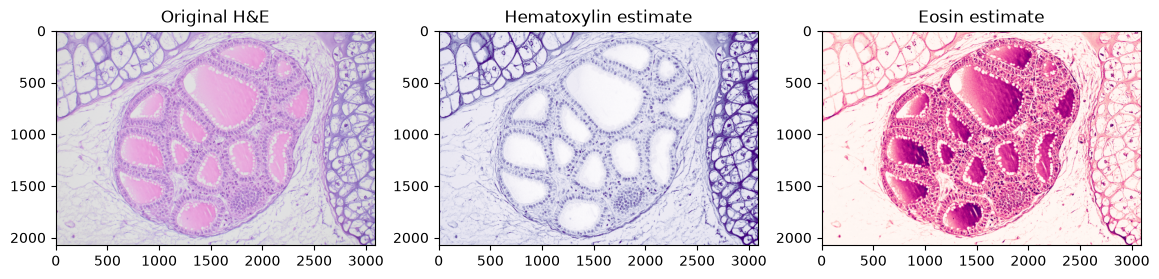

In [11]:
# Approximate H&E stain separation
from skimage.color import rgb2hed
from skimage.exposure import rescale_intensity

# Color deconvolution in the HE(D) colorspace
hed = rgb2hed(rgb)
hematoxylin = hed[:, :, 0]
eosin = hed[:, :, 1]

# Rescaling intensity (for plotting)
val_min_h, val_max_h = np.percentile(hematoxylin, (1, 99))
hematoxylin_rescaled = rescale_intensity(hematoxylin, in_range=(val_min_h, val_max_h), out_range=(0, 1))

val_min_e, val_max_e = np.percentile(eosin, (1, 99))
eosin_rescaled = rescale_intensity(eosin, in_range=(val_min_e, val_max_e), out_range=(0, 1))

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(rgb); axes[0].set_title("Original H&E")
axes[1].imshow(hematoxylin_rescaled, cmap="Purples"); axes[1].set_title("Hematoxylin estimate")
axes[2].imshow(eosin_rescaled, cmap="RdPu"); axes[2].set_title("Eosin estimate")
plt.show()

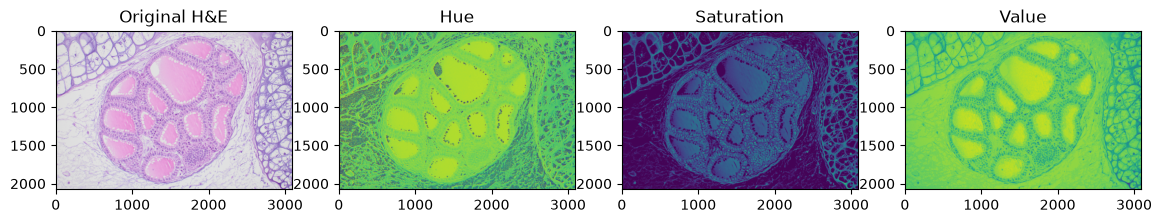

In [ ]:
# HSV color space
from skimage.color import rgb2hsv

hsv = rgb2hsv(rgb)
hue = hsv[:, :, 0]
saturation = hsv[:, :, 1]
value = hsv[:, :, 2]

# Plotting
fig, axes = plt.subplots(1, 4, figsize=(14, 5))
axes[0].imshow(rgb); axes[0].set_title("Original H&E")
axes[1].imshow(hue); axes[1].set_title("Hue")
axes[2].imshow(saturation); axes[2].set_title("Saturation")
axes[3].imshow(value); axes[3].set_title("Value")
plt.show()

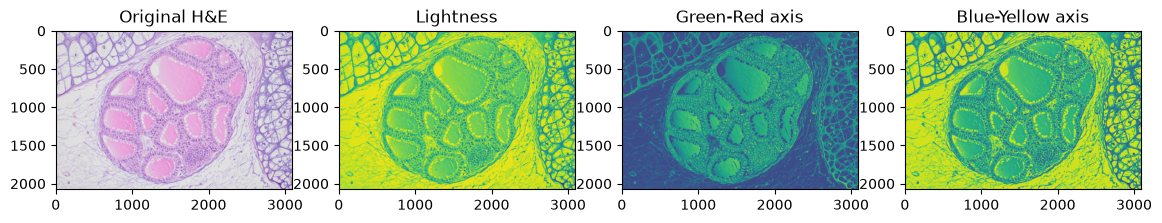

In [9]:
# LAB color space
from skimage.color import rgb2lab

lab = rgb2lab(rgb)
lightness = lab[:, :, 0]
aaxis = lab[:, :, 1]
baxis = lab[:, :, 2]

# Plotting
fig, axes = plt.subplots(1, 4, figsize=(14, 5))
axes[0].imshow(rgb); axes[0].set_title("Original H&E")
axes[1].imshow(lightness); axes[1].set_title("Lightness")
axes[2].imshow(aaxis); axes[2].set_title("Green-Red axis")
axes[3].imshow(baxis); axes[3].set_title("Blue-Yellow axis")
plt.show()

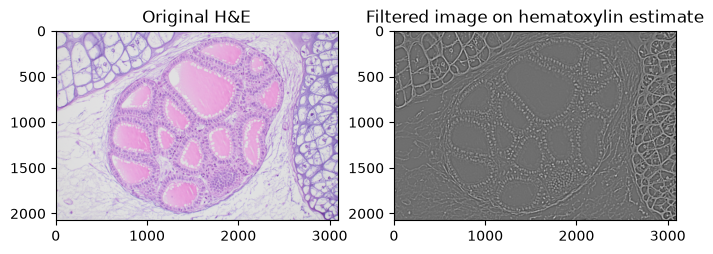

In [ ]:
# LoG filtering with scikit-image
from skimage.filters import difference_of_gaussians

filtered_image = difference_of_gaussians(hematoxylin_rescaled, 5)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(8, 5))
axes[0].imshow(rgb); axes[0].set_title("Original H&E")
axes[1].imshow(filtered_image, cmap = "grey"); axes[1].set_title(f"Filtered image on hematoxylin estimate")
plt.show()

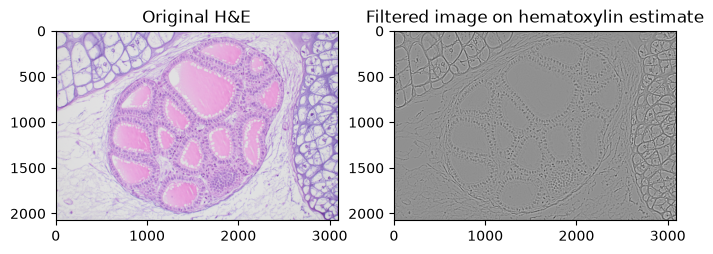

In [18]:
# LoG filtering with SciPy
from scipy import ndimage

filtered_image = ndimage.gaussian_laplace(hematoxylin_rescaled, sigma=5)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(8, 5))
axes[0].imshow(rgb); axes[0].set_title("Original H&E")
axes[1].imshow(filtered_image, cmap = "grey"); axes[1].set_title(f"Filtered image on hematoxylin estimate")
plt.show()


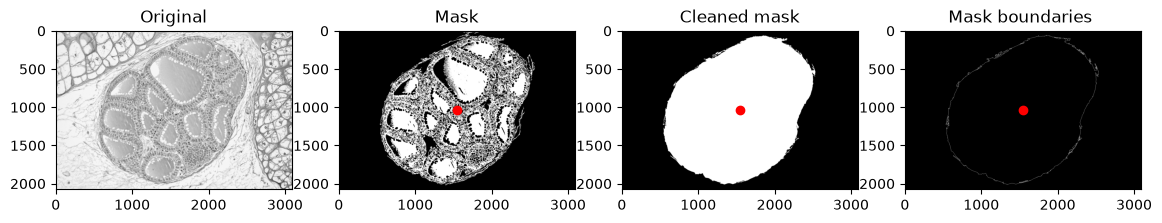

Number of components: 2
[[      0       0    3088    2076 3668414]
 [    534      56    2001    1957 2742274]]
Thyroid gland area is 2742274 px^2 (42.8% of tissue area)


In [20]:
# Strategy to segment thyroid tissue based on region growing ("seed segmentation")
from skimage import segmentation

height, width = rgb.shape[:2]
seed_point = (width/2, height/2)

# Segmentation based on region growing
mask = segmentation.flood(rgb[:, :, 1], (1500, 1038), tolerance = 25)

# Mask cleaning
mask_clean = remove_small_objects(mask, max_size=5000)
mask_clean = remove_small_holes(mask_clean, max_size=100000)

# Boundaries
boundaries = segmentation.find_boundaries(mask_clean, mode='thick')

# Plotting
fig, axes = plt.subplots(1, 4, figsize=(14, 5))
axes[0].imshow(rgb[:, :, 1],  cmap=plt.cm.gray); axes[0].set_title("Original")
axes[1].imshow(mask, cmap=plt.cm.gray); axes[1].plot(1544, 1038, 'ro') ; axes[1].set_title("Mask")
axes[2].imshow(mask_clean, cmap=plt.cm.gray); axes[2].plot(1544, 1038, 'ro') ; axes[2].set_title("Cleaned mask")
axes[3].imshow(boundaries, cmap=plt.cm.gray); axes[3].plot(1544, 1038, 'ro') ; axes[3].set_title("Mask boundaries ")
plt.show()

# Connected-component labeling
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    mask_clean,
    connectivity=8)

print("Number of components:", num_labels)
print(stats)
print("Thyroid gland area is 2742274 px^2 (42.8% of tissue area)")


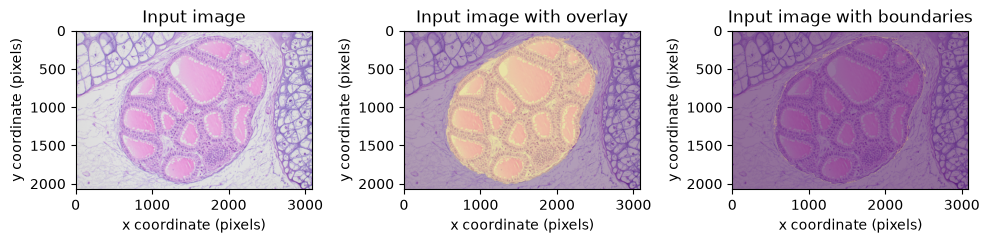

Thyroid gland area is 2742274 px^2 (42.8% of tissue area)


In [21]:
# Create an overlay of the segmented area on the original H&E
fig, axes = plt.subplots(1, 3, figsize=(10, 5))

# Ax 1: Input image
axes[0].imshow(rgb)
axes[0].set_title("Input image")
axes[0].axis("on")
axes[0].set_xlabel("x coordinate (pixels)")
axes[0].set_ylabel("y coordinate (pixels)")

# Ax 2: Input image with overlay
axes[1].imshow(rgb)
axes[1].imshow(mask_clean, alpha = 0.3)
axes[1].set_title("Input image with overlay")
axes[1].axis("on")
axes[1].set_xlabel("x coordinate (pixels)")
axes[1].set_ylabel("y coordinate (pixels)")

# Ax 3: Input image with overlay
axes[2].imshow(rgb)
axes[2].imshow(boundaries, alpha = 0.5)
axes[2].set_title("Input image with boundaries")
axes[2].axis("on")
axes[2].set_xlabel("x coordinate (pixels)")
axes[2].set_ylabel("y coordinate (pixels)")

plt.tight_layout()
plt.show()

print("Thyroid gland area is 2742274 px^2 (42.8% of tissue area)")

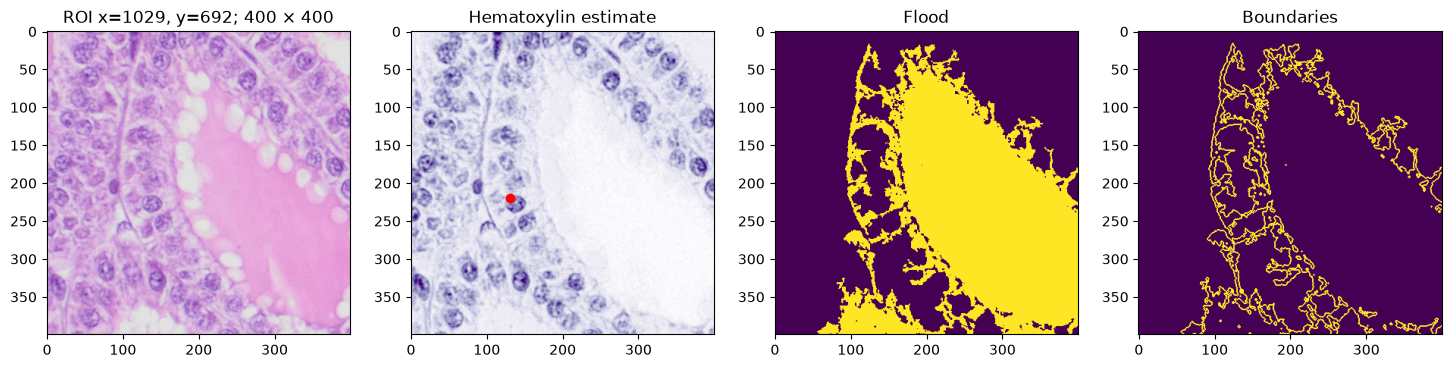

In [22]:
# Try to define the overlay at the cell scale
height, width = rgb.shape[:2]

ROI_X = width // 3
ROI_Y = height // 3
ROI_SIZE = 400

x0 = max(0, min(ROI_X, width - 1))
y0 = max(0, min(ROI_Y, height - 1))
x1 = min(width, x0 + ROI_SIZE)
y1 = min(height, y0 + ROI_SIZE)

hematoxylin_rescaled_int = (hematoxylin_rescaled * 255).astype(np.uint8)
eosin_rescaled_int = (eosin_rescaled * 255).astype(np.uint8)

roi_rgb = rgb[y0:y1, x0:x1]
roi_mask = mask[y0:y1, x0:x1]
roi_h = hematoxylin_rescaled_int[y0:y1, x0:x1]

roi_flood = segmentation.flood(roi_h, (100, 220), tolerance = 50)
roi_boundaries = segmentation.find_boundaries(roi_flood)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(roi_rgb); axes[0].set_title(f"ROI x={x0}, y={y0}; {x1-x0} × {y1-y0}")
axes[1].imshow(roi_h, cmap="Purples"); axes[1].plot(130, 220, 'ro'); axes[1].set_title(f"Hematoxylin estimate")
axes[2].imshow(roi_flood); axes[2].set_title(f"Flood")
axes[3].imshow(roi_boundaries); axes[3].set_title(f"Boundaries")
plt.show()